# Q4 — Como o curso se saiu e em qual componente foi melhor ou pior?

**Variáveis:** NT_GER, NT_FG, NT_CE · **Arquivo:** arq3 (+ arq1 para atributos do curso)

**Hipótese:** A nota média do curso fica mais distante da média do grupo em `NT_CE` do que em `NT_FG`.

In [1]:
# Centraliza bibliotecas e constantes usadas em toda a análise da Q4.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# códigos derivados em analyze.ipynb
CO_IES_UNIFOR = 555
CO_CURSO_UNIFOR_CC = 11730

DATA_DIR = "../data/2021"
TP_PRES_PRESENTE = 555
TP_PR_GER_CONSIDERADOS = [333, 555]
CO_REGIAO_NORDESTE = 2
CO_CATEGAD_PRIVADAS = [4, 5]
N_MIN_CURSO = 5
N_BOOTSTRAP = 10_000
rng = np.random.default_rng(42)

## Dados

In [2]:
# Lê as notas (arq3) e os atributos do curso (arq1); a junção é agregada por CO_CURSO, nunca por linha.
colunas_notas = ["NT_GER", "NT_FG", "NT_CE"]
notas = pd.read_csv(
    f"{DATA_DIR}/microdados2021_arq3.txt",
    sep=";",
    encoding="ISO-8859-1",
    usecols=["CO_CURSO", "TP_PRES", "TP_PR_GER", *colunas_notas],
    low_memory=False,
)
cursos = pd.read_csv(
    f"{DATA_DIR}/microdados2021_arq1.txt",
    sep=";",
    encoding="ISO-8859-1",
    usecols=["CO_CURSO", "CO_IES", "CO_GRUPO", "CO_CATEGAD", "CO_REGIAO_CURSO"],
).drop_duplicates(subset="CO_CURSO")
notas = notas.merge(cursos, on="CO_CURSO", how="left", validate="many_to_one")
notas.head()

,CO_CURSO,TP_PRES,TP_PR_GER,NT_GER,NT_FG,NT_CE,CO_IES,CO_CATEGAD,CO_GRUPO,CO_REGIAO_CURSO
0,14346,555,333.0,0.0,0.0,0.0,586,1,3202,3
1,63045,555,333.0,0.0,0.0,0.0,1820,1,1602,2
2,45498,555,333.0,0.0,0.0,0.0,24,2,1601,2
3,18312,555,333.0,0.0,0.0,0.0,666,2,3502,2
4,14349,555,333.0,0.0,0.0,0.0,586,1,2001,3


In [3]:
# Mantém só quem tem nota considerada pelo INEP e define os grupos de comparação por máscaras nomeadas.
m_presente_valido = (notas["TP_PRES"] == TP_PRES_PRESENTE) & (
    notas["TP_PR_GER"].isin(TP_PR_GER_CONSIDERADOS)
)

curso_unifor = cursos[cursos["CO_CURSO"] == CO_CURSO_UNIFOR_CC]
assert (len(curso_unifor) == 1) and (curso_unifor["CO_IES"].iloc[0] == CO_IES_UNIFOR)
CO_GRUPO_CC = curso_unifor["CO_GRUPO"].iloc[0]
print(f"CO_GRUPO de Ciência da Computação (obtido do curso da UNIFOR): {CO_GRUPO_CC}")

base = notas[m_presente_valido].copy()
m_unifor = base["CO_CURSO"] == CO_CURSO_UNIFOR_CC
m_cc_brasil = base["CO_GRUPO"] == CO_GRUPO_CC
m_cc_nordeste = (base["CO_GRUPO"] == CO_GRUPO_CC) & (
    base["CO_REGIAO_CURSO"] == CO_REGIAO_NORDESTE
)
m_cc_privadas = (base["CO_GRUPO"] == CO_GRUPO_CC) & (
    base["CO_CATEGAD"].isin(CO_CATEGAD_PRIVADAS)
)

rotulos_notas = {
    "NT_GER": "Nota geral",
    "NT_FG": "Formação geral",
    "NT_CE": "Componente específico",
}
grupos = {
    "UNIFOR CC": m_unifor,
    "CC Brasil": m_cc_brasil,
    "CC Nordeste": m_cc_nordeste,
    "CC privadas": m_cc_privadas,
}

CO_GRUPO de Ciência da Computação (obtido do curso da UNIFOR): 4004


In [4]:
# Informa quantos registros entram na análise e quais códigos de presença ficaram de fora.
escopos = {
    "CC Brasil": notas["CO_GRUPO"] == CO_GRUPO_CC,
    "UNIFOR CC": notas["CO_CURSO"] == CO_CURSO_UNIFOR_CC,
}
for rotulo, m_escopo in escopos.items():
    excluidos = notas[m_escopo & ~m_presente_valido]
    codigos = (
        excluidos["TP_PRES"].astype(str)
        + "/"
        + excluidos["TP_PR_GER"].astype("Int64").astype(str)
    )
    detalhe = ", ".join(
        f"{codigo}: {qtd}"
        for codigo, qtd in codigos.value_counts().sort_index().items()
    )
    motivo = f"{rotulo}; nota não considerada pelo INEP — TP_PRES/TP_PR_GER {detalhe}"
    n_validos = (m_escopo & m_presente_valido).sum()
    n_excluidos = len(excluidos)
    print(f"Base: {n_validos} registros válidos; {n_excluidos} excluídos ({motivo}).")

Base: 9987 registros válidos; 2746 excluídos (CC Brasil; nota não considerada pelo INEP — TP_PRES/TP_PR_GER 222/222: 2578, 222/<NA>: 2, 334/334: 16, 444/889: 6, 444/<NA>: 12, 555/<NA>: 6, 556/556: 126).
Base: 36 registros válidos; 22 excluídos (UNIFOR CC; nota não considerada pelo INEP — TP_PRES/TP_PR_GER 222/222: 22).


## Resultados

In [5]:
# Resume cada nota por grupo; esta tabela é a fonte dos números usados nos gaps e nos gráficos.
tabela_descritiva = pd.concat(
    {
        rotulo: base.loc[mascara, colunas_notas]
        .agg(["count", "mean", "median", "std"])
        .T
        for rotulo, mascara in grupos.items()
    },
    names=["Grupo", "Nota"],
)
tabela_descritiva.columns = ["n", "Média", "Mediana", "Desvio-padrão"]
tabela_descritiva["n"] = tabela_descritiva["n"].astype(int)
tabela_descritiva.round(2)

n  Média  Mediana  Desvio-padrão
Grupo       Nota                                       
UNIFOR CC   NT_GER    36  38.30    37.55          11.99
            NT_FG     36  38.74    40.10          15.85
            NT_CE     36  38.15    36.90          13.01
CC Brasil   NT_GER  9987  36.92    35.70          13.83
            NT_FG   9987  37.59    37.50          15.04
            NT_CE   9987  36.67    35.80          15.77
CC Nordeste NT_GER  2014  38.22    37.60          13.37
            NT_FG   2014  38.89    38.90          14.96
            NT_CE   2014  37.98    37.00          15.31
CC privadas NT_GER  5389  31.77    30.60          11.61
            NT_FG   5389  33.98    33.70          14.36
            NT_CE   5389  31.01    30.60          13.15

In [6]:
# Mede a distância da UNIFOR a cada grupo (bruta e em desvios-padrão), com IC 95% por bootstrap pareado dos alunos da UNIFOR.
notas_comparadas = ["NT_FG", "NT_CE"]
grupos_comparacao = ["CC Brasil", "CC Nordeste", "CC privadas"]

notas_unifor = base.loc[m_unifor, notas_comparadas].to_numpy()
indices_bootstrap = rng.integers(
    0, len(notas_unifor), size=(N_BOOTSTRAP, len(notas_unifor))
)
medias_bootstrap = pd.DataFrame(
    notas_unifor[indices_bootstrap].mean(axis=1), columns=notas_comparadas
)

linhas = []
for grupo in grupos_comparacao:
    for nota in notas_comparadas:
        media_unifor = tabela_descritiva.loc[("UNIFOR CC", nota), "Média"]
        media_grupo = tabela_descritiva.loc[(grupo, nota), "Média"]
        desvio_grupo = tabela_descritiva.loc[(grupo, nota), "Desvio-padrão"]
        ic_media = np.percentile(medias_bootstrap[nota], [2.5, 97.5])
        ic_inferior, ic_superior = (ic_media - media_grupo) / desvio_grupo
        linhas.append(
            {
                "Grupo": grupo,
                "Nota": nota,
                "Média UNIFOR": media_unifor,
                "IC 95% média UNIFOR": f"{ic_media[0]:.1f} a {ic_media[1]:.1f}",
                "Média grupo": media_grupo,
                "Gap bruto": media_unifor - media_grupo,
                "Gap padronizado": (media_unifor - media_grupo) / desvio_grupo,
                "IC 95% inferior": ic_inferior,
                "IC 95% superior": ic_superior,
            }
        )
tabela_gaps = pd.DataFrame(linhas).set_index(["Grupo", "Nota"])
tabela_gaps.round(2)

Média UNIFOR IC 95% média UNIFOR  Média grupo  Gap bruto  \
Grupo       Nota                                                              
CC Brasil   NT_FG         38.74         33.7 a 43.9        37.59       1.15   
            NT_CE         38.15         33.9 a 42.4        36.67       1.47   
CC Nordeste NT_FG         38.74         33.7 a 43.9        38.89      -0.14   
            NT_CE         38.15         33.9 a 42.4        37.98       0.17   
CC privadas NT_FG         38.74         33.7 a 43.9        33.98       4.76   
            NT_CE         38.15         33.9 a 42.4        31.01       7.13   

                   Gap padronizado  IC 95% inferior  IC 95% superior  
Grupo       Nota                                                      
CC Brasil   NT_FG             0.08            -0.26             0.42  
            NT_CE             0.09            -0.18             0.36  
CC Nordeste NT_FG            -0.01            -0.34             0.33  
            NT_CE             0.01            -0.27             0.29  
CC privadas NT_FG             0.33            -0.02             0.69  
            NT_CE             0.54             0.22             0.86

In [7]:
# Responde à hipótese: compara |gap CE| com |gap FG| em cada grupo, com IC 95% da diferença pelo mesmo bootstrap pareado.
linhas = []
for grupo in grupos_comparacao:
    medias_grupo = tabela_descritiva.loc[grupo].loc[notas_comparadas, "Média"]
    desvios_grupo = tabela_descritiva.loc[grupo].loc[notas_comparadas, "Desvio-padrão"]
    gaps_bootstrap = (medias_bootstrap - medias_grupo) / desvios_grupo
    diferenca_bootstrap = gaps_bootstrap["NT_CE"].abs() - gaps_bootstrap["NT_FG"].abs()
    gaps = tabela_gaps.loc[grupo]
    linhas.append(
        {
            "Grupo": grupo,
            "|Gap FG| bruto": abs(gaps.loc["NT_FG", "Gap bruto"]),
            "|Gap CE| bruto": abs(gaps.loc["NT_CE", "Gap bruto"]),
            "|Gap FG| padronizado": abs(gaps.loc["NT_FG", "Gap padronizado"]),
            "|Gap CE| padronizado": abs(gaps.loc["NT_CE", "Gap padronizado"]),
            "Diferença CE − FG": abs(gaps.loc["NT_CE", "Gap padronizado"])
            - abs(gaps.loc["NT_FG", "Gap padronizado"]),
            "IC 95% inferior": np.percentile(diferenca_bootstrap, 2.5),
            "IC 95% superior": np.percentile(diferenca_bootstrap, 97.5),
            "Bootstraps com CE > FG (%)": (diferenca_bootstrap > 0).mean() * 100,
        }
    )
tabela_hipotese = pd.DataFrame(linhas).set_index("Grupo")
tabela_hipotese.round(2)

,|Gap FG| bruto,|Gap CE| bruto,|Gap FG| padronizado,|Gap CE| padronizado,Diferença CE − FG,IC 95% inferior,IC 95% superior,Bootstraps com CE > FG (%)
Grupo,,,,,,,,
CC Brasil,1.15,1.47,0.08,0.09,0.02,-0.29,0.24,45.67
CC Nordeste,0.14,0.17,0.01,0.01,0.00,-0.29,0.21,42.81
CC privadas,4.76,7.13,0.33,0.54,0.21,-0.15,0.56,86.59


In [8]:
# Situa a UNIFOR entre os cursos de CC do Brasil pela média de cada curso (só cursos com n suficiente).
medias_por_curso = (
    base[m_cc_brasil]
    .groupby("CO_CURSO")
    .agg(
        n=("NT_GER", "count"),
        NT_GER=("NT_GER", "mean"),
        NT_FG=("NT_FG", "mean"),
        NT_CE=("NT_CE", "mean"),
    )
)
medias_por_curso = medias_por_curso[medias_por_curso["n"] >= N_MIN_CURSO]
n_cursos = len(medias_por_curso)

linhas = []
for nota in colunas_notas:
    media_unifor = medias_por_curso.loc[CO_CURSO_UNIFOR_CC, nota]
    linhas.append(
        {
            "Nota": nota,
            "Média UNIFOR": media_unifor,
            "Mediana das médias dos cursos": medias_por_curso[nota].median(),
            "Posição": (medias_por_curso[nota] > media_unifor).sum() + 1,
            "Cursos comparados (n ≥ 5)": n_cursos,
            "Percentil UNIFOR": (medias_por_curso[nota] < media_unifor).sum()
            / n_cursos
            * 100,
        }
    )
tabela_posicao = pd.DataFrame(linhas).set_index("Nota")
tabela_posicao.round(1)

,Média UNIFOR,Mediana das médias dos cursos,Posição,Cursos comparados (n ≥ 5),Percentil UNIFOR
Nota,,,,,
NT_GER,38.3,34.5,108,304,64.5
NT_FG,38.7,36.8,125,304,58.9
NT_CE,38.1,33.9,105,304,65.5


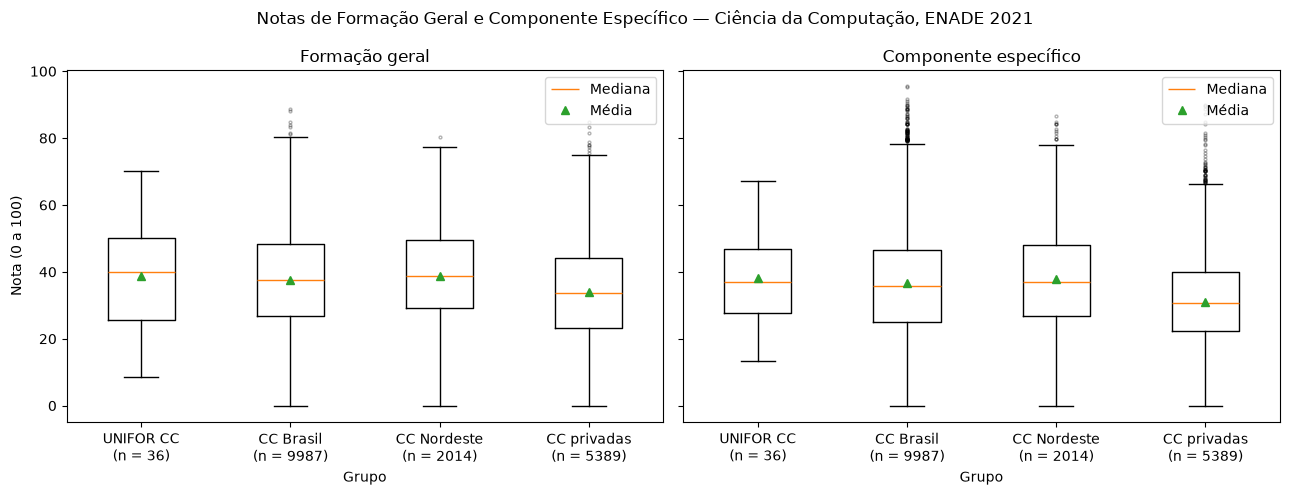

In [9]:
# Mostra a distribuição de FG e CE em cada grupo, na ordem fixa dos grupos e com o n de cada um.
fig, eixos = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for eixo, nota in zip(eixos, notas_comparadas):
    rotulos_eixo = [
        f"{grupo}\n(n = {tabela_descritiva.loc[(grupo, nota), 'n']})"
        for grupo in grupos
    ]
    caixas = eixo.boxplot(
        [base.loc[mascara, nota] for mascara in grupos.values()],
        tick_labels=rotulos_eixo,
        showmeans=True,
        flierprops={"markersize": 2, "alpha": 0.3},
    )
    eixo.set_title(rotulos_notas[nota])
    eixo.set_xlabel("Grupo")
    eixo.legend(
        [caixas["medians"][0], caixas["means"][0]],
        ["Mediana", "Média"],
        loc="upper right",
    )
eixos[0].set_ylabel("Nota (0 a 100)")
fig.suptitle(
    "Notas de Formação Geral e Componente Específico — Ciência da Computação, ENADE 2021"
)
plt.tight_layout()
plt.show()

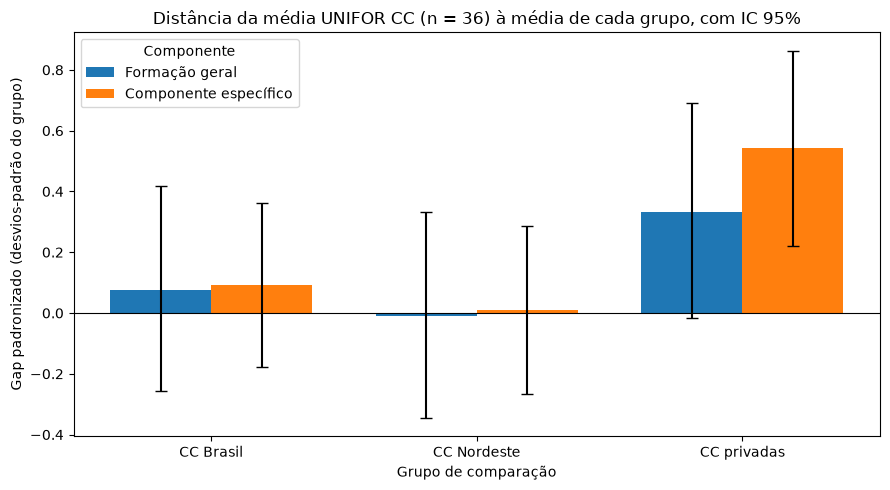

In [10]:
# Compara os gaps padronizados de FG e CE por grupo, com o IC 95% vindo da tabela de gaps.
n_unifor = tabela_descritiva.loc[("UNIFOR CC", "NT_GER"), "n"]
posicoes = np.arange(len(grupos_comparacao))
largura = 0.38

fig, eixo = plt.subplots(figsize=(9, 5))
for deslocamento, nota in zip([-largura / 2, largura / 2], notas_comparadas):
    gaps = tabela_gaps.xs(nota, level="Nota").loc[grupos_comparacao]
    erro = [
        gaps["Gap padronizado"] - gaps["IC 95% inferior"],
        gaps["IC 95% superior"] - gaps["Gap padronizado"],
    ]
    eixo.bar(
        posicoes + deslocamento,
        gaps["Gap padronizado"],
        largura,
        yerr=erro,
        capsize=4,
        label=rotulos_notas[nota],
    )
eixo.axhline(0, color="black", linewidth=0.8)
eixo.set_xticks(posicoes, grupos_comparacao)
eixo.set_xlabel("Grupo de comparação")
eixo.set_ylabel("Gap padronizado (desvios-padrão do grupo)")
eixo.set_title(
    f"Distância da média UNIFOR CC (n = {n_unifor}) à média de cada grupo, com IC 95%"
)
eixo.legend(title="Componente")
plt.tight_layout()
plt.show()

## Conclusão

- **Hipótese: INCONCLUSIVA.** Nas estimativas pontuais, o |gap| em CE supera o de FG nos três grupos, mas a diferença entre eles (|gap CE| − |gap FG|, em desvios) não se distingue de zero em nenhum grupo pelo bootstrap pareado. Contra CC Brasil ela é +0,02 (IC 95% de −0,29 a 0,24) e contra CC Nordeste é 0,00 (IC de −0,29 a 0,21); em menos da metade das reamostragens o CE fica mais distante, e no Nordeste a ordem se inverte quando um único registro de prova em branco entra ou sai da base. Só contra CC privadas há indício a favor: +0,21 (IC de −0,15 a 0,56), com o CE mais distante em 87% das reamostragens.
- **Como o curso se saiu:** a média geral da UNIFOR CC (38,3) fica um pouco acima da de CC Brasil (36,9), igual à de CC Nordeste (38,2) e acima da de CC privadas (31,8). Entre 304 cursos de CC com n ≥ 5, a UNIFOR está no percentil 64,5 em NT_GER (108.ª posição).
- **Melhor e pior componente:** em posição relativa, o CE é o ponto mais forte (percentil 65,5; 0,54 desvio acima das privadas, com IC de 0,22 a 0,86, que não inclui zero). A FG é o mais fraco (percentil 58,9; o IC contra as privadas, de −0,02 a 0,69, inclui zero). Diante de CC Brasil e CC Nordeste, nenhum gap se distingue de zero.
- **Limitações:** a UNIFOR tem só 36 estudantes com nota (22 ausentes ficaram de fora), por isso os ICs são largos. O ENADE 2021 foi aplicado no contexto da pandemia. As notas descrevem o desempenho, mas não explicam suas causas.